# Supplementary Figure 3 — ACC and STAD TMB axis examples

Scatter of TMB axis score vs log(TMB) for two example cancer types (selected by strongest high–low TMB delta):
- **ACC** (below global median)
- **STAD** (above global median)

Source: `local/exploratory/27_fig4.ipynb`

Output: `results/figures/supplementary/supp_fig3/3a_acc_stad_tmb_axis.pdf`

In [5]:
import os
import socket
import sys

import matplotlib as mpl
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

mpl.rcParams["pdf.fonttype"] = 42
mpl.rcParams["svg.fonttype"] = "none"

hostname = socket.gethostname()
if "scg" in hostname:
    BASE_DIR = "/labs/mwinslow/Karen/protein-master/v2_pancan_batch_corrected"
else:
    BASE_DIR = os.path.expanduser(
        "~/Documents/research/scg/protein-master/v2_pancan_batch_corrected"
    )

WORKING_DIR = f"{BASE_DIR}/analysis/01_axis_analysis/bh"
OUT_DIR = f"{BASE_DIR}/results/figures/supplementary/supp_fig3"
os.makedirs(OUT_DIR, exist_ok=True)

sys.path.insert(0, f"{BASE_DIR}/local/figures")
from palette import COLORS

palette_tmb = {"Low TMB": COLORS["low"], "High TMB": COLORS["high"]}


def rasterize_figure(fig):
    """Rasterize line/marker artists in PDF; text stays vector."""
    from matplotlib.collections import LineCollection, PathCollection, PolyCollection
    from matplotlib.lines import Line2D

    for ax in fig.axes:
        for artist in ax.get_children():
            if isinstance(artist, (Line2D, PathCollection, LineCollection, PolyCollection)):
                artist.set_rasterized(True)

In [ ]:
df_axis = pd.read_parquet(
    f"{WORKING_DIR}/axis_sample_scores/tcga_xena/axis_sample_level.parquet"
)

df_axis_split = df_axis.copy()
df_axis_split["tmb_bin"] = (
    df_axis_split
    .groupby("cancer_type")["log_mut"]
    .transform(lambda x: pd.qcut(x, q=2, labels=["Low TMB", "High TMB"]))
)

In [ ]:
global_median = df_axis["TMB_axis_score"].median()

summary = (
    df_axis_split
    .groupby(["cancer_type", "tmb_bin"], observed=True)["TMB_axis_score"]
    .median()
    .reset_index()
)
summary_wide = summary.pivot(
    index="cancer_type", columns="tmb_bin", values="TMB_axis_score"
).reset_index()
summary_wide.columns.name = None
summary_wide["delta"] = summary_wide["High TMB"] - summary_wide["Low TMB"]

below = summary_wide[
    (summary_wide["Low TMB"] < global_median)
    & (summary_wide["High TMB"] < global_median)
]
above = summary_wide[
    (summary_wide["Low TMB"] > global_median)
    & (summary_wide["High TMB"] > global_median)
]

example_below = below.sort_values("delta", ascending=False).iloc[0]["cancer_type"]
example_above = above.sort_values("delta", ascending=False).iloc[0]["cancer_type"]
print(example_below, example_above)

ACC STAD


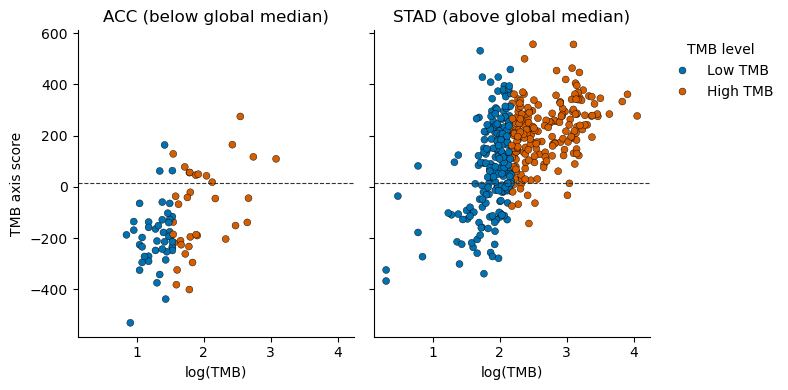

In [ ]:
title_map = {
    example_below: f"{example_below} (below global median)",
    example_above: f"{example_above} (above global median)",
}

subset = df_axis_split[
    df_axis_split["cancer_type"].isin([example_below, example_above])
]

g = sns.FacetGrid(subset, col="cancer_type", height=4, sharey=True)
g.map_dataframe(
    sns.scatterplot,
    x="log_mut",
    y="TMB_axis_score",
    hue="tmb_bin",
    hue_order=["Low TMB", "High TMB"],
    palette=palette_tmb,
    s=25,
    edgecolor=COLORS["black"],
    linewidth=0.3,
)

for ax in g.axes.flat:
    current_title = ax.get_title().split(" = ")[-1]
    ax.set_title(title_map.get(current_title, current_title))
    ax.axhline(global_median, linestyle="--", color=COLORS["dark_gray"], linewidth=0.8)

g.set_axis_labels("log(TMB)", "TMB axis score")
plt.legend(title="TMB level", bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
plt.tight_layout()
# Keep scatter vector (few points) so Adobe export stays sharp; do not rasterize.
plt.savefig(f"{OUT_DIR}/3a_acc_stad_tmb_axis.pdf", dpi=1200)
plt.show()